# 12주차 실습_첫번째_순환 신경망 (RNN / LSTM) 
> 2026711051 박민지

### [1] 실습 진행 관련 설명

순차 데이터를 처리하는 순환 신경망에 대한 실습을 진행하고자 한다. 실습은 크게 두 가지로 구성되어 있다.

- 직접 함수를 구현하는 방법 (numpy)
- Tensorflow 2.0 / Keras 라이브러리를 이용한 방법

먼저 numpy 로 RNN 셀과 LSTM 셀의 순전파를 직접 구현하여 내부 연산을 확인하고,
그 결과를 Keras 의 `SimpleRNN`, `LSTM` 층이 계산한 값과 비교하여 **구현이 정확한지 검증**한다.
그 다음 실제 데이터(IMDB 영화평)를 이용하여 `SimpleRNN`, `LSTM`, `GRU` 의 성능을 비교한다.

In [1]:
# [0] 환경 설정  ─ 런타임을 새로 시작했다면 이 셀을 가장 먼저 실행한다.
#     (Windows VS Code 실행) Colab 전용 apt-get 나눔 폰트 설치 대신 Windows 기본 글꼴 Malgun Gothic 을 쓴다.
#     Windows 의 TensorFlow 는 GPU 를 쓰지 않으므로 CPU 로 학습한다.
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
print('한글 폰트 설정 완료 :', plt.rcParams['font.family'])

한글 폰트 설정 완료 : ['Malgun Gothic']


## [2] 코드 구현의 흐름

- **(1) (데이터 측면)** 순차 데이터의 형태 `(batch, timesteps, features)` 이해하기
- **(2) (모델 측면)** numpy 로 RNN 셀 / LSTM 셀 순전파 직접 구현하기
- **(3) (검증)** Keras 층의 가중치를 가져와 직접 구현한 결과와 비교하기
- **(4) (실험)** 기울기 소실 현상을 수치적으로 관찰하기
- **(5) (데이터 측면)** IMDB 영화평 데이터 불러오기 · 정수 인코딩 · 패딩
- **(6) (모델 측면)** Embedding + SimpleRNN / LSTM / GRU 분류 모형 정의
- **(7) (학습 과정)** 세 모형을 학습하고 학습 곡선 비교
- **(8) (성능 평가)** 검증 정확도 비교 및 문장 길이(maxlen)에 따른 성능 변화 관찰

## (공통) 라이브러리 불러오기

In [2]:
# (로컬 VS Code) 이 노트북에 필요한 패키지를 설치한다. 이미 설치된 패키지는 건너뛴다.
#   Colab 전용 나눔 폰트 설치(apt-get)는 빼고, 한글 폰트는 위에서 설정한 Malgun Gothic 을 쓴다.
%pip install -q numpy matplotlib tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
try:
    from tensorflow.keras.utils import pad_sequences        # TF 2.9 / Keras 2.9 이상
except ImportError:
    from tensorflow.keras.preprocessing.sequence import pad_sequences

# 실습 결과를 재현하기 위해 난수 시드를 고정한다.
np.random.seed(0)
tf.random.set_seed(0)

print('tensorflow version :', tf.__version__)

tensorflow version : 2.21.0


# 1. 순환 신경망의 직접 구현 (numpy)

## 1) 순차 데이터의 형태

RNN 에 들어가는 입력은 항상 **3차원 텐서**이다.

$$\text{(batch\_size,\; timesteps,\; input\_dim)}$$

- `batch_size` : 한 번에 처리하는 문장(순차열)의 수
- `timesteps` : 순차열의 길이 (문장의 단어 수)
- `input_dim` : 한 시점의 특징 벡터 차원 (임베딩 차원)

아래에서는 이해를 돕기 위해 `batch_size=1`, `timesteps=4`, `input_dim=3` 인 아주 작은 입력을 사용한다.

> **[설명]** 순차 데이터는 **순서가 의미를 갖는 데이터**로, RNN은 이를 `(batch, timesteps, input_dim)` 3차원 텐서로 받는다. 입력 모양을 먼저 맞춰 두어야 뒤에서 Keras 층에 넣을 때 차원 오류를 피할 수 있다.

In [4]:
# (1) (데이터 측면) 아주 작은 순차 데이터 만들기

timesteps = 4     # 순차열의 길이 (문장의 단어 수)
input_dim = 3     # 한 시점의 입력 차원 (임베딩 차원)
hidden_units = 2  # 은닉 상태의 차원

# (timesteps, input_dim) 형태의 입력 순차열
inputs = np.array([[1.0, 0.0, 0.5],
                   [0.0, 1.0, 0.2],
                   [0.5, 0.5, 0.0],
                   [1.0, 1.0, 1.0]])

print('입력 순차열 shape :', inputs.shape)
print(inputs)

# Keras 에 넣을 때는 배치 차원을 추가하여 3차원으로 만들어 주어야 한다.
inputs_batch = inputs.reshape(1, timesteps, input_dim)
print('\nKeras 입력 shape :', inputs_batch.shape, '  # (batch, timesteps, input_dim)')

입력 순차열 shape : (4, 3)
[[1.  0.  0.5]
 [0.  1.  0.2]
 [0.5 0.5 0. ]
 [1.  1.  1. ]]

Keras 입력 shape : (1, 4, 3)   # (batch, timesteps, input_dim)


> **[결과]** 단어 4개짜리 문장 하나를, 단어마다 숫자 3개로 표현한 표 `(4, 3)`으로 만들었다.
> - Keras는 '문장 여러 개'를 한꺼번에 받도록 되어 있어서, 문장이 1개뿐이어도 맨 앞에 개수 1을 붙여 `(1, 4, 3)`으로 바꿔 주었다.
> - 쉽게 말해 `(문장 수, 단어 수, 단어 하나의 숫자 개수)` 순서다. 이 모양이 아래 모든 셀에서 쓰인다.

## 2) RNN 셀 순전파 직접 구현

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$

- $W_x$ : `(input_dim, hidden_units)` — 입력 → 은닉
- $W_h$ : `(hidden_units, hidden_units)` — 은닉 → 은닉 (순환 가중치)
- $b$ : `(hidden_units,)` — 편향

**모든 시점이 동일한 $W_x, W_h, b$ 를 공유한다는 점**(가중치 공유)에 주의하면서 구현한다.

> **[설명]** RNN 셀은 지금 들어온 단어와 방금까지 읽은 내용의 요약을 섞어 새 요약을 만드는 장치다. 모든 시점이 같은 가중치를 돌려 쓰므로, 문장 길이가 달라도 파라미터 수는 그대로다.

In [5]:
# (2) (모델 측면) RNN 셀 한 시점의 순전파를 직접 구현

def rnn_cell_forward(x_t, h_prev, W_x, W_h, b):
    '''RNN 셀의 한 시점 순전파.

    x_t    : (input_dim,)      현재 시점의 입력
    h_prev : (hidden_units,)   직전 시점의 은닉 상태
    반환   : (hidden_units,)   현재 시점의 은닉 상태
    '''
    # 입력에 대한 선형 변환 + 직전 은닉 상태에 대한 선형 변환 + 편향
    z = np.dot(x_t, W_x) + np.dot(h_prev, W_h) + b
    # tanh 를 적용해 출력 범위를 (-1, 1) 로 제한한다.
    h_t = np.tanh(z)
    return h_t


def rnn_forward(inputs, W_x, W_h, b):
    '''순차열 전체에 대한 RNN 순전파.

    inputs : (timesteps, input_dim)
    반환   : (timesteps, hidden_units)  모든 시점의 은닉 상태
    '''
    T = inputs.shape[0]
    hidden_units = W_h.shape[0]

    # 초기 은닉 상태 h(0) 은 영벡터로 초기화한다.
    h_prev = np.zeros(hidden_units)
    hidden_states = np.zeros((T, hidden_units))

    for t in range(T):
        h_t = rnn_cell_forward(inputs[t], h_prev, W_x, W_h, b)
        hidden_states[t] = h_t
        # 현재 은닉 상태가 다음 시점의 '직전 은닉 상태'가 된다. (순환)
        h_prev = h_t

    return hidden_states

In [6]:
# (2-2) 임의의 가중치로 직접 구현한 RNN 을 실행해 보자.

W_x = np.random.randn(input_dim, hidden_units) * 0.5
W_h = np.random.randn(hidden_units, hidden_units) * 0.5
b = np.zeros(hidden_units)

hidden_states = rnn_forward(inputs, W_x, W_h, b)

print('모든 시점의 은닉 상태 shape :', hidden_states.shape)
for t, h in enumerate(hidden_states):
    print('h(%d) = %s' % (t + 1, np.round(h, 4)))

print('\n마지막 은닉 상태 h(T) =', np.round(hidden_states[-1], 4))
print('  → many-to-one 구조에서는 이 h(T) 하나만 분류기로 넘긴다.')

모든 시점의 은닉 상태 shape : (4, 2)
h(1) = [ 0.8738 -0.0442]
h(2) = [0.7982 0.7387]
h(3) = [0.7726 0.636 ]
h(4) = [0.9899 0.7182]

마지막 은닉 상태 h(T) = [0.9899 0.7182]
  → many-to-one 구조에서는 이 h(T) 하나만 분류기로 넘긴다.


> **[결과]** RNN이 문장을 한 단어씩 읽으며 '지금까지 읽은 내용의 요약'(은닉 상태)을 4번 고쳐 쓰는 과정을 직접 계산했다. 감정 분류처럼 문장 끝에서 답 하나만 내는 문제(many-to-one)에서는 문장을 다 읽은 뒤의 요약 `h(4)`만 분류기에 넘긴다.

## 3) Keras `SimpleRNN` 과 결과 비교 (검증)

직접 구현한 함수가 정확한지 확인하려면, **Keras 층에 동일한 가중치를 넣고** 결과를 비교하면 된다.

`SimpleRNN` 층의 가중치는 `[kernel, recurrent_kernel, bias]` 순서의 리스트이며,
각각 우리가 정의한 $W_x$, $W_h$, $b$ 에 대응한다.

> **[설명]** 가장 확실한 방법은 검증된 라이브러리에 같은 가중치를 넣고 출력을 비교해보는 것이다. 이렇게 하면 수식을 제대로 이해했는지와 Keras 가중치 배치를 동시에 확인할 수 있다.

**SimpleRNN**: Keras(`keras.layers`)의 클래스로, $h_t=\tanh(x_tW_x+h_{t-1}W_h+b)$를 계산하는 기본 순환 층이다.
- `SimpleRNN(units)`: 은닉 상태 차원 `units`
- `return_sequences=True`: 모든 시점의 은닉 상태 `(batch, T, units)` 반환 (기본은 마지막 시점만 `(batch, units)`)
- `return_state=True`: 출력과 함께 마지막 은닉 상태를 따로 반환
- `get_weights()` / `set_weights([kernel, recurrent_kernel, bias])`: 가중치를 꺼내거나 넣음

**np.allclose(a, b, atol)**: NumPy 함수로, 두 배열의 모든 원소 차이가 허용 오차 안에 있으면 `True`를 돌려준다. 부동소수점 계산 결과를 비교할 때 `==` 대신 쓴다.

In [7]:
# (3) (검증) Keras SimpleRNN 에 동일한 가중치를 주입하고 결과를 비교

# return_sequences=True 로 지정하면 모든 시점의 은닉 상태를 반환한다.
rnn_layer = keras.layers.SimpleRNN(hidden_units,
                                   return_sequences=True,
                                   return_state=True)

# 층을 한 번 호출해 가중치를 생성(build)한 뒤 우리 가중치로 교체한다.
_ = rnn_layer(inputs_batch)
rnn_layer.set_weights([W_x, W_h, b])

keras_seq, keras_last = rnn_layer(inputs_batch)
keras_seq = keras_seq.numpy()[0]   # (timesteps, hidden_units)

print('직접 구현 결과')
print(np.round(hidden_states, 6))
print('\nKeras SimpleRNN 결과')
print(np.round(keras_seq, 6))
print('\n최대 오차 :', np.max(np.abs(hidden_states - keras_seq)))
assert np.allclose(hidden_states, keras_seq, atol=1e-5), '구현이 일치하지 않습니다!'
print('→ 두 결과가 일치한다. 직접 구현이 정확하다.')

직접 구현 결과
[[ 0.873797 -0.044212]
 [ 0.798152  0.738656]
 [ 0.772595  0.636046]
 [ 0.989854  0.718239]]

Keras SimpleRNN 결과
[[ 0.873797 -0.044212]
 [ 0.798152  0.738656]
 [ 0.772595  0.636046]
 [ 0.989854  0.718239]]

최대 오차 : 1.1047111647677355e-07
→ 두 결과가 일치한다. 직접 구현이 정확하다.


> **[결과]** 
> - 직접 만든 RNN과 Keras의 `SimpleRNN`에 똑같은 가중치를 넣고 답을 맞대어 보았다.
> - 두 결과의 가장 큰 차이가 `0.00000011`(1.1e-07)이었다. 컴퓨터가 소수를 저장할 때 생기는 아주 작은 반올림 차이일 뿐, 사실상 같은 값이다. 즉 수식 $h_t=\tanh(x_tW_x+h_{t-1}W_h+b)$를 제대로 이해하고 구현했다는 뜻이다.

## 4) LSTM 셀 순전파 직접 구현

$$
\begin{aligned}
f_t &= \sigma(W_f\,[h_{t-1}, x_t] + b_f) &&\text{(망각 게이트)}\\
i_t &= \sigma(W_i\,[h_{t-1}, x_t] + b_i) &&\text{(입력 게이트)}\\
\tilde{C}_t &= \tanh(W_C\,[h_{t-1}, x_t] + b_C) &&\text{(후보값)}\\
C_t &= f_t \odot C_{t-1} + i_t \odot \tilde{C}_t &&\text{(셀 상태 갱신)}\\
o_t &= \sigma(W_o\,[h_{t-1}, x_t] + b_o) &&\text{(출력 게이트)}\\
h_t &= o_t \odot \tanh(C_t) &&\text{(은닉 상태)}
\end{aligned}
$$

Keras 의 `LSTM` 층은 4 개의 게이트 가중치를 **하나의 큰 행렬로 이어 붙여** 저장한다.
순서는 `[i, f, C̃, o]` 이므로, 열 방향으로 `hidden_units` 씩 잘라서 사용하면 된다.

> **[설명]** LSTM은 RNN에 장기 기억 노트와 그 노트를 지우고/쓰고/읽는 세 게이트를 붙인 구조다. 셀 상태를 덧셈으로 갱신하므로 먼 과거의 정보를 오래 들고 갈 수 있다.

In [8]:
# (2-3) (모델 측면) LSTM 셀 순전파를 직접 구현

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def lstm_forward(inputs, W, U, b, units):
    '''LSTM 순전파 (Keras 가중치 배치 순서 [i, f, C, o] 를 그대로 사용).

    inputs : (timesteps, input_dim)
    W      : (input_dim, 4*units)    kernel
    U      : (units, 4*units)        recurrent_kernel
    b      : (4*units,)              bias
    반환   : 모든 시점의 은닉 상태, 셀 상태
    '''
    T = inputs.shape[0]
    h_prev = np.zeros(units)   # 은닉 상태 (단기 기억)
    C_prev = np.zeros(units)   # 셀 상태  (장기 기억)

    hs = np.zeros((T, units))
    Cs = np.zeros((T, units))

    for t in range(T):
        # 4 개의 선형 변환을 한 번에 계산한 뒤 잘라서 사용한다.
        z = np.dot(inputs[t], W) + np.dot(h_prev, U) + b
        z_i = z[0 * units:1 * units]   # 입력 게이트
        z_f = z[1 * units:2 * units]   # 망각 게이트
        z_C = z[2 * units:3 * units]   # 후보값
        z_o = z[3 * units:4 * units]   # 출력 게이트

        i_t = sigmoid(z_i)             # 무엇을 새로 저장할지
        f_t = sigmoid(z_f)             # 무엇을 버릴지
        C_tilde = np.tanh(z_C)         # 저장할 후보값
        o_t = sigmoid(z_o)             # 무엇을 내보낼지

        # 핵심 : 셀 상태는 '곱'이 아니라 '덧셈'으로 갱신된다.
        C_t = f_t * C_prev + i_t * C_tilde
        h_t = o_t * np.tanh(C_t)

        hs[t], Cs[t] = h_t, C_t
        h_prev, C_prev = h_t, C_t

    return hs, Cs

**LSTM**: Keras(`keras.layers`)의 클래스로, 게이트 3개(입력·망각·출력)와 셀 상태를 가진 순환 층이다.
- `LSTM(units, return_sequences, return_state)`: `return_state=True`면 `[출력, h_T, C_T]` 3개를 반환
- `get_weights()` → `[kernel (input_dim, 4·units), recurrent_kernel (units, 4·units), bias (4·units,)]`

**가중치 읽는 법**
- 4개 게이트 가중치가 열 방향으로 `[i, f, C̃, o]` 순서로 이어 붙어 있다.
- `units`개씩 잘라 쓰면 각 게이트의 가중치가 된다.

In [9]:
# (3-2) (검증) Keras LSTM 의 가중치를 그대로 가져와 직접 구현 결과와 비교

lstm_layer = keras.layers.LSTM(hidden_units,
                               return_sequences=True,
                               return_state=True)
keras_h_seq, keras_h_last, keras_C_last = lstm_layer(inputs_batch)

# Keras 가 초기화한 가중치를 그대로 꺼내 온다.
W, U, b = lstm_layer.get_weights()
print('kernel W shape           :', W.shape, ' # (input_dim, 4*units)')
print('recurrent_kernel U shape :', U.shape, ' # (units, 4*units)')
print('bias b shape             :', b.shape, ' # (4*units,)')

my_h, my_C = lstm_forward(inputs, W, U, b, hidden_units)

print('\n직접 구현한 은닉 상태')
print(np.round(my_h, 6))
print('\nKeras LSTM 은닉 상태')
print(np.round(keras_h_seq.numpy()[0], 6))
print('\n최대 오차 :', np.max(np.abs(my_h - keras_h_seq.numpy()[0])))
assert np.allclose(my_h, keras_h_seq.numpy()[0], atol=1e-5)
print('→ LSTM 구현도 정확하다.')

kernel W shape           : (3, 8)  # (input_dim, 4*units)
recurrent_kernel U shape : (2, 8)  # (units, 4*units)
bias b shape             : (8,)  # (4*units,)

직접 구현한 은닉 상태
[[-0.163547 -0.064075]
 [-0.138786 -0.001367]
 [-0.246151  0.022074]
 [-0.384584 -0.090832]]

Keras LSTM 은닉 상태
[[-0.163547 -0.064075]
 [-0.138786 -0.001367]
 [-0.246151  0.022074]
 [-0.384584 -0.090832]]

최대 오차 : 3.554180735831913e-08
→ LSTM 구현도 정확하다.


In [10]:
# (3-3) 게이트 값을 직접 관찰해 보자. (망각 게이트가 실제로 0~1 사이인지 확인)

z = np.dot(inputs[0], W) + np.dot(np.zeros(hidden_units), U) + b
u = hidden_units
gates = {
    'i (입력 게이트)': sigmoid(z[0 * u:1 * u]),
    'f (망각 게이트)': sigmoid(z[1 * u:2 * u]),
    'C̃ (후보값)': np.tanh(z[2 * u:3 * u]),
    'o (출력 게이트)': sigmoid(z[3 * u:4 * u]),
}
for name, value in gates.items():
    print('%-16s : %s' % (name, np.round(value, 4)))

print('\n· 게이트(i, f, o)는 시그모이드이므로 반드시 0 ~ 1 사이의 값이다.')
print('· 후보값(C̃)은 tanh 이므로 -1 ~ 1 사이의 값이다.')

i (입력 게이트)       : [0.6184 0.3108]
f (망각 게이트)       : [0.7721 0.7513]
C̃ (후보값)         : [-0.3998 -0.2885]
o (출력 게이트)       : [0.6749 0.7166]

· 게이트(i, f, o)는 시그모이드이므로 반드시 0 ~ 1 사이의 값이다.
· 후보값(C̃)은 tanh 이므로 -1 ~ 1 사이의 값이다.


> **[결과]** LSTM도 직접 구현한 결과와 Keras `LSTM`의 결과를 비교했다.
> - 가장 큰 차이가 `0.000000036`(3.6e-08)으로, 이번에도 사실상 똑같았다. Keras가 게이트 가중치 4개를 `[입력, 망각, 후보, 출력]` 순서로 붙여 둔다는 점을 제대로 짚었다는 뜻이다.
> - 첫 단어를 읽을 때 망각 게이트 값은 `[0.77, 0.75]`였다. 쉽게 말해 '예전 기억의 약 75~77%는 남기고 나머지는 지운다'는 뜻이다. 게이트는 시그모이드를 거치므로 항상 0과 1 사이 값이 나온다.

## 5) 기울기 소실 현상 관찰

BPTT 에서 $k$ 시점 이전으로 기울기를 전파하려면 순환 가중치를 $k$ 번 곱해야 한다.
따라서 기울기의 크기는 대략 $|W_h|^k$ 에 비례한다.

$$\frac{\partial h_t}{\partial h_{t-k}} = \prod_{j=1}^{k} W_h^{\top}\,\mathrm{diag}\big(\tanh'(\cdot)\big)$$

순환 가중치의 크기에 따라 기울기가 어떻게 변하는지 직접 계산해 보자.

> **[설명]** 기울기 소실은 **역전파 때 같은 값을 여러 번 곱하면서 기울기가 0으로 줄어드는 현상**이고, 반대로 커지면 폭주한다. 기본 RNN이 긴 문장에서 앞부분을 잊어버리는 원인을 숫자로 확인하기 위해 계산한다.

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (6 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


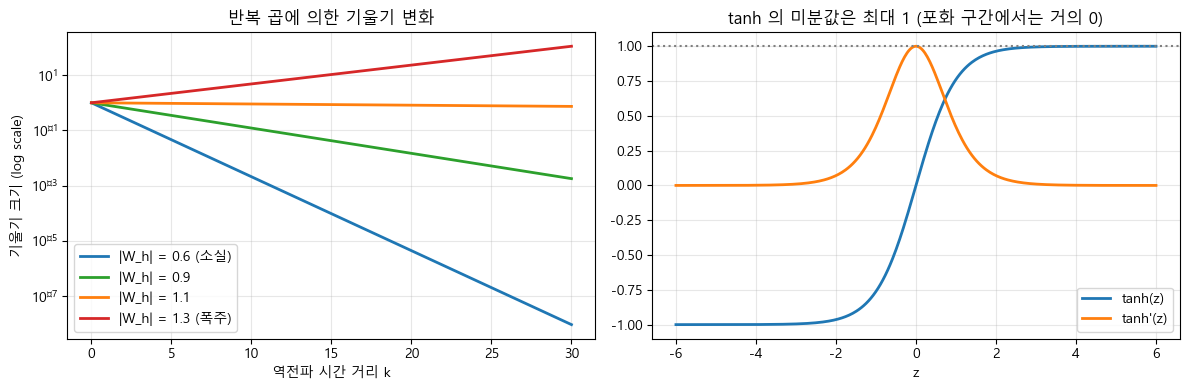

In [11]:
# (4) (실험) 순환 가중치 크기에 따른 기울기 변화

def gradient_norm_over_time(w, k_max=30, tanh_deriv=0.9):
    '''|W_h| = w 일 때, k 시점 전으로 전파된 기울기의 상대적 크기.'''
    ks = np.arange(0, k_max + 1)
    return ks, (w * tanh_deriv) ** ks


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for w, c, label in [(0.6, 'tab:blue', '|W_h| = 0.6 (소실)'),
                    (0.9, 'tab:green', '|W_h| = 0.9'),
                    (1.1, 'tab:orange', '|W_h| = 1.1'),
                    (1.3, 'tab:red', '|W_h| = 1.3 (폭주)')]:
    ks, g = gradient_norm_over_time(w)
    plt.semilogy(ks, g, color=c, lw=2, label=label)
plt.xlabel('역전파 시간 거리 k')
plt.ylabel('기울기 크기 (log scale)')
plt.title('반복 곱에 의한 기울기 변화')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
zz = np.linspace(-6, 6, 400)
plt.plot(zz, np.tanh(zz), lw=2, label="tanh(z)")
plt.plot(zz, 1 - np.tanh(zz) ** 2, lw=2, label="tanh'(z)")
plt.axhline(1.0, ls=':', color='gray')
plt.title("tanh 의 미분값은 최대 1 (포화 구간에서는 거의 0)")
plt.xlabel('z')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# (4-2) 구체적인 숫자로 확인하기

print('%-12s %-14s %-14s %-14s' % ('k (시간 거리)', '|W_h|=0.6', '|W_h|=0.9', '|W_h|=1.3'))
print('-' * 58)
for k in [1, 5, 10, 20, 30, 50]:
    row = [(w * 0.9) ** k for w in (0.6, 0.9, 1.3)]
    print('%-12d %-14.3e %-14.3e %-14.3e' % (k, row[0], row[1], row[2]))

print('\n· |W_h| < 1 : k 가 커지면 기울기가 0 으로 수렴 → 기울기 소실')
print('· |W_h| x tanh\' > 1 : k 가 커지면 기울기가 발산 → 기울기 폭주')
print('  (여기서는 tanh\'=0.9 를 가정했으므로 |W_h| > 1.11 부터 발산한다.')
print('   |W_h|=1.1 곡선이 완만하게 감소하는 것이 그 경계 부근이다.)')
print('· 즉, 기본 RNN 으로는 먼 과거와의 관계(장기 의존성)를 학습하기 어렵다.')

k (시간 거리)    |W_h|=0.6      |W_h|=0.9      |W_h|=1.3     
----------------------------------------------------------
1            5.400e-01      8.100e-01      1.170e+00     
5            4.592e-02      3.487e-01      2.192e+00     
10           2.108e-03      1.216e-01      4.807e+00     
20           4.445e-06      1.478e-02      2.311e+01     
30           9.372e-09      1.797e-03      1.111e+02     
50           4.166e-14      2.656e-05      2.566e+03     

· |W_h| < 1 : k 가 커지면 기울기가 0 으로 수렴 → 기울기 소실
· |W_h| x tanh' > 1 : k 가 커지면 기울기가 발산 → 기울기 폭주
  (여기서는 tanh'=0.9 를 가정했으므로 |W_h| > 1.11 부터 발산한다.
   |W_h|=1.1 곡선이 완만하게 감소하는 것이 그 경계 부근이다.)
· 즉, 기본 RNN 으로는 먼 과거와의 관계(장기 의존성)를 학습하기 어렵다.


> **[결과]** '같은 숫자를 여러 번 곱하면 어떻게 되는가'를 계산해 보았다. 역전파에서 기울기가 과거로 한 칸 갈 때마다 이 곱셈이 한 번씩 일어난다.
> - 곱하는 값이 1보다 작으면(예: $|W_h|=0.6$) 30칸 뒤에는 `0.000000009`로 사실상 0이 된다. → **기울기 소실**: 먼 과거 단어에서 포착할 신호가 사라진다.
> - 곱하는 값이 1보다 크면(예: $|W_h|=1.3$) 30칸 뒤에는 `111` 배로 커진다. → **기울기 폭주**: 가중치가 한 번에 크게 흔들린다.
> - 그래서 기본 RNN은 멀리있는 문장 앞쪽 내용을 뒤까지 잘 기억하지 못한다.

### LSTM 은 왜 다른가?

LSTM 의 셀 상태는 곱이 아니라 **덧셈**으로 갱신되므로

$$\frac{\partial C_t}{\partial C_{t-1}} = f_t$$

가 되어, 반복 곱해지는 항이 **학습되는 값 $f_t$** 로 대체된다.
망각 게이트가 열려 있으면($f_t \approx 1$) 기울기가 먼 과거까지 거의 그대로 전달된다.

> **[설명]** LSTM의 셀 상태 경로에서는 반복해서 곱해지는 값이 고정된 $W_h$가 아니라 학습되는 망각 게이트 $f_t$ 다. 모델이 $f_t$를 1가까이 두면 기울기가 먼 과거까지 거의 줄지 않고 전달된다.

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (22 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


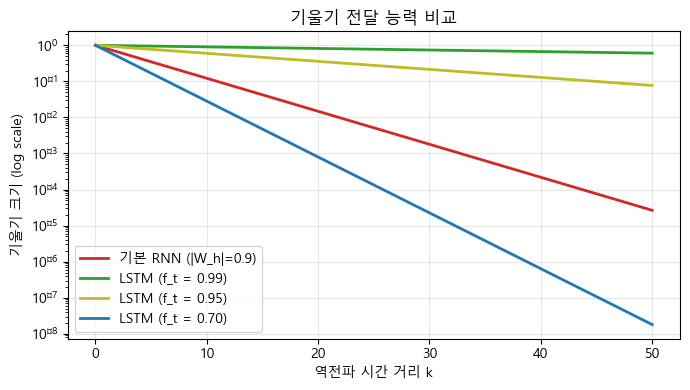

In [13]:
# (4-3) LSTM 의 기울기 흐름과 비교 (망각 게이트 값에 따른 변화)

plt.figure(figsize=(7, 4))
ks = np.arange(0, 51)

# 기본 RNN
plt.semilogy(ks, (0.9 * 0.9) ** ks, lw=2, color='tab:red',
             label='기본 RNN (|W_h|=0.9)')

# LSTM : 망각 게이트 값이 클수록 기울기가 잘 보존된다.
for f, c in [(0.99, 'tab:green'), (0.95, 'tab:olive'), (0.7, 'tab:blue')]:
    plt.semilogy(ks, f ** ks, lw=2, color=c, label='LSTM (f_t = %.2f)' % f)

plt.xlabel('역전파 시간 거리 k')
plt.ylabel('기울기 크기 (log scale)')
plt.title('기울기 전달 능력 비교')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

> **[결과]** 같은 50칸을 거슬러 갈 때, 기본 RNN과 LSTM에서 기울기가 얼마나 남는지 비교했다.
> - 기본 RNN($|W_h|=0.9$)은 매 칸 0.81씩 곱해져서 50칸 뒤에는 약 `0.000027`만 남는다. 처음 신호의 0.003%수준이라 사실상 사라진 셈이다.
> - LSTM은 망각 게이트 값 $f_t$를 곱하는데, 이 값이 0.99처럼 1에 가까우면 50칸 뒤에도 $0.99^{50}\approx0.61$, 즉 **61%가 그대로 남는다**.
> - 정리하면, LSTM은 '기억을 얼마나 남길지'(망각 게이트)를 스스로 배워서 1가까이 둘 수 있기 때문에 먼 과거까지 학습 신호를 전달할 수 있다.

# 2. 실제 데이터에 적용하기 : IMDB 영화평 감정 분류

## 1) 데이터 불러오기

- **IMDB dataset** : 영화 리뷰 50,000 건에 대해 긍정(1) / 부정(0) 라벨이 붙어 있는 데이터
- Keras 에 내장되어 있고, 이미 **정수 인코딩**이 되어 있다. (단어 → 빈도 순위 정수)
- `num_words=10000` 으로 지정하면 가장 자주 등장하는 상위 10,000 개 단어만 사용한다.

이 문제는 **many-to-one** 구조에 해당한다. (문장 전체를 읽고 → 긍정/부정 하나를 출력)

**keras.datasets.imdb**: Keras의 내장 데이터셋 모듈로, IMDB 영화평 50,000건(학습 25,000 / 평가 25,000)을 정수 인코딩된 상태로 내려받는다.
- `load_data(num_words=10000)`: 빈도 상위 10,000개 단어만 남기고 나머지는 OOV(2)로 바꿈
- `get_word_index()`: `{단어: 빈도 순위}` 사전. 실제 인덱스는 예약 번호(0패딩, 1시작, 2 OOV) 때문에 순위 + 3이다.

In [14]:
# (5) (데이터 측면) IMDB 데이터 불러오기

vocab_size = 10000   # 사용할 단어 사전의 크기
maxlen = 200         # 문장을 자를 최대 길이 (= 펼칠 시점 수)

(x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(
    num_words=vocab_size)

print('학습 데이터 수 :', len(x_train))
print('평가 데이터 수 :', len(x_test))
print('\n첫 번째 리뷰 (정수 인코딩된 상태, 앞 20개) :')
print(x_train[0][:20])
print('첫 번째 리뷰의 라벨 :', y_train[0], '(1=긍정, 0=부정)')

lengths = np.array([len(s) for s in x_train])
print('\n리뷰 길이 - 평균 : %.1f, 중앙값 : %d, 최댓값 : %d'
      % (lengths.mean(), np.median(lengths), lengths.max()))

학습 데이터 수 : 25000
평가 데이터 수 : 25000

첫 번째 리뷰 (정수 인코딩된 상태, 앞 20개) :
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
첫 번째 리뷰의 라벨 : 1 (1=긍정, 0=부정)

리뷰 길이 - 평균 : 238.7, 중앙값 : 178, 최댓값 : 2494


In [15]:
# (5-2) (데이터 측면) 정수 인코딩을 원래 단어로 되돌려 확인해 보기

word_index = keras.datasets.imdb.get_word_index()
# 0, 1, 2 는 각각 패딩, 문장 시작, 미등록 단어(OOV)로 예약되어 있으므로 3을 더한다.
index_to_word = {v + 3: k for k, v in word_index.items()}
index_to_word[0] = '<pad>'
index_to_word[1] = '<sos>'
index_to_word[2] = '<unk>'

decoded = ' '.join(index_to_word.get(i, '?') for i in x_train[0][:40])
print('복원한 리뷰 (앞 40 단어) :')
print(decoded)

복원한 리뷰 (앞 40 단어) :
<sos> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <unk> is an amazing actor and now the same being director <unk> father came


**pad_sequences**: Keras(`keras.utils`)의 함수로, 길이가 제각각인 정수 시퀀스를 같은 길이의 2차원 배열로 맞춘다.
- `maxlen`: 맞출 길이 / `padding='post'`: 짧으면 뒤에 0을 채움 (`'pre'`는 앞)
- `truncating='post'`: 길면 뒤를 자름
- 예전 경로 `keras.preprocessing.sequence.pad_sequences`를 대신한다.

패딩 후 학습 데이터 shape : (25000, 200)  # (batch, timesteps)

짧은 리뷰의 패딩 결과 (뒤쪽 0 이 PAD 토큰) :
원래 길이 : 43
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


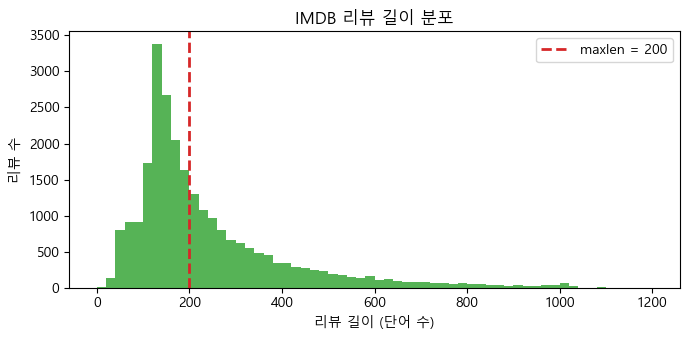

In [16]:
# (5-3) (데이터 측면) 패딩으로 문장 길이 맞추기

x_train_pad = pad_sequences(
    x_train, maxlen=maxlen, padding='post', truncating='post')
x_test_pad = pad_sequences(
    x_test, maxlen=maxlen, padding='post', truncating='post')

print('패딩 후 학습 데이터 shape :', x_train_pad.shape,
      ' # (batch, timesteps)')
print('\n짧은 리뷰의 패딩 결과 (뒤쪽 0 이 PAD 토큰) :')
short_idx = int(np.argmin([len(s) for s in x_train[:100]]))
print('원래 길이 :', len(x_train[short_idx]))
print(x_train_pad[short_idx][-30:])

# 시각화 : 리뷰 길이 분포
plt.figure(figsize=(7, 3.5))
plt.hist(lengths, bins=60, range=(0, 1200), color='tab:green', alpha=0.8)
plt.axvline(maxlen, color='tab:red', ls='--', lw=2, label='maxlen = %d' % maxlen)
plt.xlabel('리뷰 길이 (단어 수)')
plt.ylabel('리뷰 수')
plt.title('IMDB 리뷰 길이 분포')
plt.legend()
plt.tight_layout()
plt.show()

> **[결과]** IMDB 영화평을 학습용 25,000개, 평가용 25,000개 불러왔다.
> - 리뷰 길이는 평균 239단어, 중앙값은 178단어로, 몇몇 아주 긴 리뷰가 평균을 끌어올린다.
> - 신경망에 넣으려면 모든 리뷰의 길이가 같아야 하므로 `pad_sequences`로 200단어에 맞췄다. 짧은 리뷰는 뒤에 0을 채우고, 긴 리뷰는 200단어 뒤를 잘라 냈다. 그 결과 리뷰 25,000개, 단어 200개 크기의 표가 만들어졌다.

## 2) 모델 구현 : SimpleRNN / LSTM / GRU

세 모형의 차이는 **순환 층 하나뿐**이며, 나머지 구조는 완전히 동일하게 두어
순환 층 종류에 따른 성능 차이만 관찰할 수 있도록 한다.

```
Embedding(10000 → 64)  →  순환 층(64)  →  Dense(1, sigmoid)
```

- `mask_zero=True` : 패딩(0) 위치를 연산에서 제외하도록 마스킹한다.
- 출력이 이진 분류이므로 손실 함수는 `binary_crossentropy` 를 사용한다.

> **[설명]** 세 순환층(SimpleRNN·LSTM·GRU)을 나머지 구조와 학습 조건을 똑같이 둔 채 바꿔 끼우면, 성능 차이를 순환 층 하나의 효과로 볼 수 있다. 게이트가 실제 데이터에서 얼마나 도움이 되는지, 그 대가로 파라미터와 시간이 얼마나 드는지 확인한다.

**Embedding**: Keras(`keras.layers`)의 클래스로, 단어 정수 ID를 학습 가능한 밀집 벡터로 바꾼다.
- `Embedding(input_dim=vocab_size, output_dim=64)`: `(batch, T)` → `(batch, T, 64)`
- `mask_zero=True`: ID 0(패딩) 위치에 마스크를 만들어, 뒤따르는 순환 층이 그 시점을 건너뛰게 한다.

**GRU**: Keras(`keras.layers`)의 클래스로, 리셋·업데이트 게이트 2개만 쓰는 순환 층이다. 셀 상태가 따로 없어 LSTM보다 파라미터가 약 3/4이다.

**count_params()**: 층이나 모델의 학습 가능한 파라미터 수를 돌려준다.

In [17]:
# (6) (모델 측면) 순환 층만 바꿔 끼울 수 있는 모형 정의 함수

embedding_dim = 64
hidden_dim = 64


def build_model(rnn_type='LSTM'):
    # rnn_type : 'SimpleRNN' | 'LSTM' | 'GRU''
    if rnn_type == 'SimpleRNN':
        rnn_layer = keras.layers.SimpleRNN(hidden_dim)
    elif rnn_type == 'LSTM':
        rnn_layer = keras.layers.LSTM(hidden_dim)
    elif rnn_type == 'GRU':
        rnn_layer = keras.layers.GRU(hidden_dim)
    else:
        raise ValueError('알 수 없는 rnn_type : %s' % rnn_type)

    model = keras.Sequential([
        keras.layers.Input(shape=(maxlen,)),
        keras.layers.Embedding(vocab_size, embedding_dim, mask_zero=True),
        rnn_layer,
        keras.layers.Dense(1, activation='sigmoid'),
    ], name=rnn_type)

    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model


# 파라미터 수를 비교해 보자. (LSTM 은 게이트 3개 + 후보값 1개 = 선형 변환 4개이므로 약 4배)
for t in ['SimpleRNN', 'LSTM', 'GRU']:
    m = build_model(t)
    rnn_params = m.layers[1].count_params()
    print('%-10s 순환 층 파라미터 수 : %7d' % (t, rnn_params))

SimpleRNN  순환 층 파라미터 수 :    8256
LSTM       순환 층 파라미터 수 :   33024
GRU        순환 층 파라미터 수 :   24960


In [18]:
# (6-2) 모델 구조 확인

model = build_model('LSTM')
model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

**model.fit**: Keras 모델의 학습 메서드로, 미니배치 경사하강법으로 가중치를 갱신하고 `History` 객체를 돌려준다.
- `epochs`, `batch_size`: 학습 반복 수와 미니배치 크기
- `validation_split=0.2`: 학습 데이터의 뒤쪽 20%를 검증용으로 떼어 매 에폭 평가
- `hist.history`: `{'loss', 'accuracy', 'val_loss', 'val_accuracy'}` 에폭별 기록

In [19]:
# (7) (학습 과정) 세 모형을 같은 조건으로 학습

EPOCHS = 5
BATCH_SIZE = 128

histories = {}
for rnn_type in ['SimpleRNN', 'LSTM', 'GRU']:
    print('\n' + '=' * 60)
    print('  %s 학습 시작' % rnn_type)
    print('=' * 60)

    tf.random.set_seed(0)   # 모형 간 공정한 비교를 위해 초기화 시드를 고정
    model = build_model(rnn_type)
    hist = model.fit(x_train_pad, y_train,
                     epochs=EPOCHS,
                     batch_size=BATCH_SIZE,
                     validation_split=0.2,
                     verbose=1)
    histories[rnn_type] = hist.history


  SimpleRNN 학습 시작


Epoch 1/5



  1/157 ━━━━━━━━━━━━━━━━━━━━ 5:07 2s/step - accuracy: 0.5000 - loss: 0.7091


  2/157 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - accuracy: 0.4961 - loss: 0.6980


  3/157 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - accuracy: 0.4948 - loss: 0.6983


  4/157 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.4902 - loss: 0.6996 

... (2,366 outputs left out)


154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.9240 - loss: 0.2001


155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9238 - loss: 0.2000


156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9238 - loss: 0.2000


157/157 ━━━━━━━━━━━━━━━━━━━━ 19s 120ms/step - accuracy: 0.9238 - loss: 0.1999 - val_accuracy: 0.8260 - val_loss: 0.5224


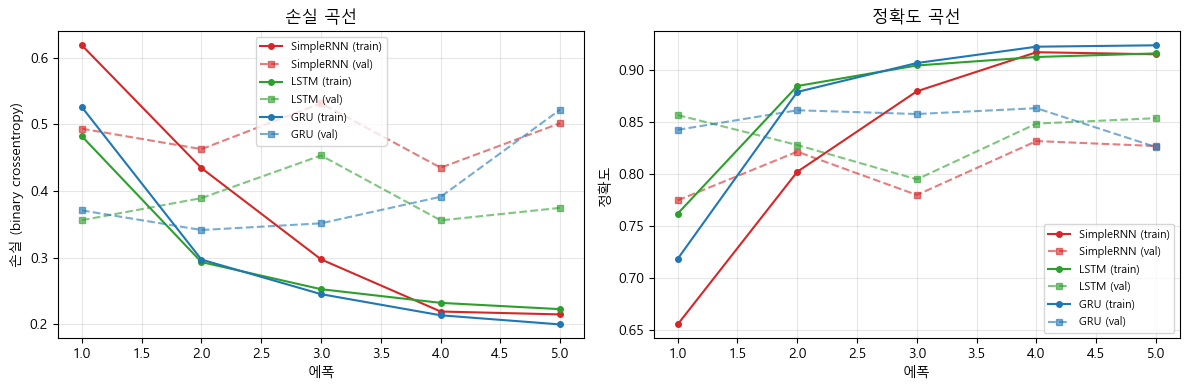

모형           최고 검증 정확도       
------------------------------
SimpleRNN    0.8318          
LSTM         0.8568          
GRU          0.8634          


In [20]:
# (8) (성능 평가) 학습 곡선 비교

colors = {'SimpleRNN': 'tab:red', 'LSTM': 'tab:green', 'GRU': 'tab:blue'}

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for name, h in histories.items():
    ep = np.arange(1, len(h['loss']) + 1)
    plt.plot(ep, h['loss'], '-o', ms=4, color=colors[name], label='%s (train)' % name)
    plt.plot(ep, h['val_loss'], '--s', ms=4, color=colors[name],
             label='%s (val)' % name, alpha=0.6)
plt.xlabel('에폭')
plt.ylabel('손실 (binary crossentropy)')
plt.title('손실 곡선')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
for name, h in histories.items():
    ep = np.arange(1, len(h['accuracy']) + 1)
    plt.plot(ep, h['accuracy'], '-o', ms=4, color=colors[name],
             label='%s (train)' % name)
    plt.plot(ep, h['val_accuracy'], '--s', ms=4, color=colors[name],
             label='%s (val)' % name, alpha=0.6)
plt.xlabel('에폭')
plt.ylabel('정확도')
plt.title('정확도 곡선')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('%-12s %-16s' % ('모형', '최고 검증 정확도'))
print('-' * 30)
for name, h in histories.items():
    print('%-12s %-16.4f' % (name, max(h['val_accuracy'])))

### 결과 해석

- `SimpleRNN` 은 학습이 불안정하거나 검증 정확도가 낮게 머무는 경우가 많다.
  → 리뷰가 200 단어에 이르므로 **장기 의존성**을 학습해야 하는데, 기울기 소실 때문에 잘 되지 않는다.
- `LSTM` 과 `GRU` 는 게이트 구조 덕분에 더 높고 안정적인 성능을 보인다.
- 단, 파라미터 수가 많아 학습 시간은 더 오래 걸린다.

In [21]:
# (8-2) (성능 평가) 문장 최대 길이(maxlen)에 따른 성능 변화
#  · maxlen 이 곧 '펼치는 시점 수' = '학습해야 하는 의존 거리'이다.
#  · 시간이 오래 걸리므로 에폭 수를 줄여서 실행한다.

def run_experiment(rnn_type, maxlen_value, epochs=3):
    xtr = pad_sequences(
        x_train, maxlen=maxlen_value, padding='post', truncating='post')

    tf.random.set_seed(0)
    if rnn_type == 'SimpleRNN':
        rnn_layer = keras.layers.SimpleRNN(hidden_dim)
    else:
        rnn_layer = keras.layers.LSTM(hidden_dim)

    model = keras.Sequential([
        keras.layers.Input(shape=(maxlen_value,)),
        keras.layers.Embedding(vocab_size, embedding_dim, mask_zero=True),
        rnn_layer,
        keras.layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy', metrics=['accuracy'])
    hist = model.fit(xtr, y_train, epochs=epochs, batch_size=128,
                     validation_split=0.2, verbose=0)
    return max(hist.history['val_accuracy'])


maxlen_list = [50, 100, 200, 400]
results = {'SimpleRNN': [], 'LSTM': []}

for L in maxlen_list:
    for t in ['SimpleRNN', 'LSTM']:
        acc = run_experiment(t, L)
        results[t].append(acc)
        print('maxlen=%3d  %-10s  검증 정확도 = %.4f' % (L, t, acc))

maxlen= 50  SimpleRNN   검증 정확도 = 0.7624


maxlen= 50  LSTM        검증 정확도 = 0.7694


maxlen=100  SimpleRNN   검증 정확도 = 0.6444


maxlen=100  LSTM        검증 정확도 = 0.8290


maxlen=200  SimpleRNN   검증 정확도 = 0.8026


maxlen=200  LSTM        검증 정확도 = 0.8664


maxlen=400  SimpleRNN   검증 정확도 = 0.8064


maxlen=400  LSTM        검증 정확도 = 0.8788


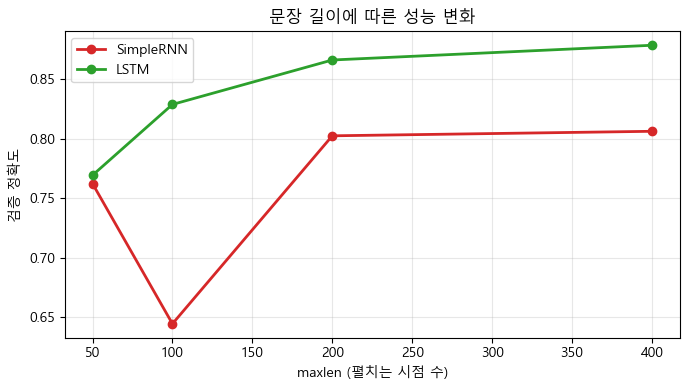

· maxlen 이 커질수록 SimpleRNN 과 LSTM 의 성능 차이가 벌어지는지 확인해 보자.
· 이것이 바로 기울기 소실 / 장기 의존성 문제의 실제 영향이다.


In [22]:
# (8-3) 실험 결과 시각화

plt.figure(figsize=(7, 4))
for t, c in [('SimpleRNN', 'tab:red'), ('LSTM', 'tab:green')]:
    plt.plot(maxlen_list, results[t], '-o', lw=2, color=c, label=t)
plt.xlabel('maxlen (펼치는 시점 수)')
plt.ylabel('검증 정확도')
plt.title('문장 길이에 따른 성능 변화')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('· maxlen 이 커질수록 SimpleRNN 과 LSTM 의 성능 차이가 벌어지는지 확인해 보자.')
print('· 이것이 바로 기울기 소실 / 장기 의존성 문제의 실제 영향이다.')

> **[결과]** 순환 층만 바꿔 가며 세 모형을 똑같은 조건으로 학습시켰다.
> - **파라미터 수**: SimpleRNN 8,256개, GRU 24,960개, LSTM 33,024개. 게이트가 많을수록 배울 값도 많아진다.
> - **성능**(최고 검증 정확도): GRU 86.3% > LSTM 85.7% > SimpleRNN 83.2%. 게이트가 있는 모형이 2~3%p 더 잘 맞혔다.
> - **문장 길이 실험**: 리뷰를 50단어만 볼 때는 SimpleRNN과 LSTM의 차이가 0.7%p로 거의 없었지만, 400단어까지 보게 하니 LSTM이 앞섰다(87.9% 대 80.6%).
> - 즉 문장이 길어질수록 앞 내용을 잊어버리는 SimpleRNN의 약점이 드러나고, 기억을 오래 유지하는 LSTM의 장점이 커진다.

## 3) 예측 결과 확인

In [23]:
# (8-4) 실제 리뷰에 대한 예측 확인

tf.random.set_seed(0)
best_model = build_model('LSTM')
best_model.fit(x_train_pad, y_train, epochs=3, batch_size=128,
               validation_split=0.2, verbose=1)

test_loss, test_acc = best_model.evaluate(x_test_pad, y_test, verbose=0)
print('\n평가 데이터 정확도 : %.4f' % test_acc)

probs = best_model.predict(x_test_pad[:5], verbose=0).ravel()
for i, p in enumerate(probs):
    text = ' '.join(index_to_word.get(j, '?') for j in x_test[i][:30])
    print('\n[리뷰 %d] %s ...' % (i + 1, text))
    print('  예측 확률 = %.3f  → 예측 : %s / 실제 : %s'
          % (p, '긍정' if p > 0.5 else '부정', '긍정' if y_test[i] == 1 else '부정'))

Epoch 1/3



  1/157 ━━━━━━━━━━━━━━━━━━━━ 3:25 1s/step - accuracy: 0.4766 - loss: 0.6936


  2/157 ━━━━━━━━━━━━━━━━━━━━ 20s 134ms/step - accuracy: 0.4805 - loss: 0.6931


  3/157 ━━━━━━━━━━━━━━━━━━━━ 20s 133ms/step - accuracy: 0.4870 - loss: 0.6931


  4/157 ━━━━━━━━━━━━━━━━━━━━ 22s 145ms/step - accuracy: 0.4980 - loss: 0.6929


  5/157 ━━━━━━━━━━━━━━━━━━━━ 22s 146ms/step - accuracy: 0.4984 - loss: 0.6929

... (467 outputs left out)


156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.9145 - loss: 0.2320


157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 143ms/step - accuracy: 0.9146 - loss: 0.2318 - val_accuracy: 0.8416 - val_loss: 0.3577



평가 데이터 정확도 : 0.8310



[리뷰 1] <sos> please give this one a miss br br <unk> <unk> and the rest of the cast rendered terrible performances the show is flat flat flat br br i don't ...
  예측 확률 = 0.069  → 예측 : 부정 / 실제 : 부정

[리뷰 2] <sos> this film requires a lot of patience because it focuses on mood and character development the plot is very simple and many of the scenes take place on the ...
  예측 확률 = 0.980  → 예측 : 긍정 / 실제 : 긍정

[리뷰 3] <sos> many animation buffs consider <unk> <unk> the great forgotten genius of one special branch of the art puppet animation which he invented almost single <unk> and as it happened ...
  예측 확률 = 0.332  → 예측 : 부정 / 실제 : 긍정

[리뷰 4] <sos> i generally love this type of movie however this time i found myself wanting to kick the screen since i can't do that i will just complain about it ...
  예측 확률 = 0.349  → 예측 : 부정 / 실제 : 부정

[리뷰 5] <sos> like some other people wrote i'm a die hard mario fan and i loved this game br br this game starts slightly boring but trust me it's worth it ..

> **[결과]** LSTM을 3에폭 학습시킨 뒤, 처음 보는 테스트 리뷰 25,000개 중 83.1%를 맞혔다.
> - 예시 리뷰 5개 중 4개를 맞혔다. 'flat flat flat'처럼 부정 표현이 뚜렷한 리뷰 1은 긍정 확률 0.07로 확실하게 부정이라고 판단했다.
> - 틀린 리뷰 3개는 실제로는 긍정이지만 긍정 확률 0.33으로 부정이라고 예측했다. 리뷰 앞부분이 애니메이션 작가 소개 위주이고 'great', 'genius' 정도 말고는 감정이 뚜렷하게 드러나지 않아 판단이 어려웠던 것으로 보인다.
> - 확률이 0.5 근처일수록 모델이 헷갈린다는 뜻이고, 0이나 1에 가까울수록 자신 있게 판단한 것이다.

---
# [과제] 실습 1

아래 네 문항을 코드 셀에 직접 작성하여 완성한 뒤, 실행 결과가 포함된 노트북을 제출한다.

### 과제 1-1. GRU 셀 직접 구현하기 (30점)

위에서 구현한 `lstm_forward` 를 참고하여 **GRU 셀의 순전파** `gru_forward` 를 numpy 로 직접 구현하고,
Keras `GRU` 층의 결과와 일치하는지 `np.allclose` 로 검증하라.

$$
\begin{aligned}
r_t &= \sigma(W_r\,[h_{t-1}, x_t] + b_r) \\
z_t &= \sigma(W_z\,[h_{t-1}, x_t] + b_z) \\
\tilde{h}_t &= \tanh\big(W_h\,x_t + U_h\,(r_t \odot h_{t-1}) + b_h\big) \\
h_t &= z_t \odot h_{t-1} + (1-z_t) \odot \tilde{h}_t
\end{aligned}
$$

(Keras·PyTorch 구현이자 Cho et al.(2014)의 표기. Chung et al.(2014)은 $h_t=(1-z_t)\odot h_{t-1}+z_t\odot\tilde{h}_t$ 로 쓴다)

**힌트**
- Keras `GRU` 의 가중치 배치 순서는 `[z, r, h]` 이다.
- Keras 는 기본값이 `reset_after=True` 이므로 bias 가 `(2, 3*units)` 형태이다.
  구현을 단순히 하려면 `keras.layers.GRU(units, reset_after=False)` 로 층을 만들어 비교하라.


In [24]:
# [과제 1-1] GRU 셀 직접 구현하기
# Keras 의 GRU(reset_after=False) 와 같은 결과가 나오는지 확인한다.
#   가중치 순서는 [z(업데이트), r(리셋), h(후보)] 이며,
#   W:(input_dim, 3*units), U:(units, 3*units), b:(3*units,)

def gru_forward(inputs, W, U, b, units):
    """GRU 순전파를 직접 구현하시오. (Keras 가중치 순서 : [z, r, h])
    inputs : (batch, time, input_dim) → 반환 : (batch, time, units)"""
    # 과제 1-1 : z=sigmoid(xWz+hUz+bz), r=sigmoid(xWr+hUr+br),
    #            h~=tanh(xWh+(r*h)Uh+bh), h=z*h_prev+(1-z)*h~ 로 구현하시오.
    def sigmoid(x):
        return 1.0 / (1.0 + np.exp(-x))

    B, T, _ = inputs.shape
    U_ = units
    h = np.zeros((B, U_), dtype='float32')
    outs = []
    for t in range(T):
        x = inputs[:, t, :]
        xz, xr, xh = x @ W[:, :U_], x @ W[:, U_:2 * U_], x @ W[:, 2 * U_:]
        hz, hr = h @ U[:, :U_], h @ U[:, U_:2 * U_]
        z = sigmoid(xz + hz + b[:U_])
        r = sigmoid(xr + hr + b[U_:2 * U_])
        # reset_after=False : 리셋 게이트를 h 에 먼저 곱한 뒤 U_h 를 적용한다
        hh = np.tanh(xh + (r * h) @ U[:, 2 * U_:] + b[2 * U_:])
        h = z * h + (1.0 - z) * hh
        outs.append(h)
    return np.stack(outs, axis=1).astype('float32')



# ---- 아래 블록은 위 TODO 를 채운 뒤 정상 동작합니다 ----
try:
    _sample = np.random.RandomState(0).randn(2, 5, 8).astype('float32')
    _gru = keras.layers.GRU(hidden_units, reset_after=False, return_sequences=True)
    _ = _gru(_sample)                              # 가중치 생성을 위한 1회 호출
    _W, _U, _b = [w.numpy() for w in _gru.weights]

    mine = gru_forward(_sample, _W, _U, _b, hidden_units)
    keras_out = _gru(_sample).numpy()
    print('직접 구현 결과 형태 :', mine.shape, ' Keras 결과 형태 :', keras_out.shape)
    print('두 결과가 일치하는가 :', np.allclose(mine, keras_out, atol=1e-5))
    assert np.allclose(mine, keras_out, atol=1e-5), '두 결과가 다릅니다. 게이트 순서를 확인하세요.'
except NotImplementedError as e:
    print('▶ 미구현 :', e)

직접 구현 결과 형태 : (2, 5, 2)  Keras 결과 형태 : (2, 5, 2)
두 결과가 일치하는가 : True


**과제 1-1 서술형**

**[구현]** Keras 가중치를 `[z, r, h]` 순서로 잘라 쓰되, 후보값을 계산할 때 리셋 게이트를 직전 은닉 상태에 먼저 곱한 뒤 `U_h`를 적용했다. 이 순서가 `reset_after=False`의 정의라서, 순서를 바꾸면 Keras 결과와 맞지 않는다.

**[결과]** 입력 `(2, 5, 8)`에 대해 직접 구현과 Keras `GRU`의 출력이 모두 `(2, 5, 2)`였고, `np.allclose(..., atol=1e-5)`가 `True`를 돌려주었다.

**[해석]** LSTM과 비교하면, GRU는 셀 상태를 따로 두지 않고, `h = z⊙h_prev + (1−z)⊙h̃` 한 식으로 '얼마나 남기고 얼마나 새로 쓸지'를 함께 정한다. 선형 변환이 4개에서 3개로 줄어, 위 실습에서도 순환 층 파라미터가 LSTM 33,024개 대비 GRU 24,960개로 약 3/4이었다.

### 과제 1-2. 양방향 LSTM 성능 비교 (20점)

`keras.layers.Bidirectional(keras.layers.LSTM(64))` 를 사용한 모형을 추가로 학습시켜,
단방향 LSTM 과 검증 정확도 · 파라미터 수 · 학습 시간을 비교하는 표를 만들고 결과를 해석하라.


**Bidirectional**: Keras(`keras.layers`)의 래퍼 클래스로, 순환 층을 정방향·역방향 두 벌로 복제해 실행하고 두 출력을 합친다.
- `Bidirectional(LSTM(64))`: 정방향 h와 역방향 h를 이어 붙여 `(batch, 128)` 출력
- `merge_mode='concat'`(기본): 합치는 방식 (`'sum'`, `'ave'`, `'mul'`도 가능)
- 파라미터 수는 감싼 층의 정확히 2배다.

LSTM (단방향)       학습 완료 (152.8 초)


BiLSTM (양방향)     학습 완료 (430.4 초)

모형                       순환층 파라미터          전체 파라미터        최고 검증 정확도       학습 시간(초)
------------------------------------------------------------------------------------
LSTM (단방향)                  33024           673089           0.8658          152.8
BiLSTM (양방향)                66048           706177           0.8720          430.4

· 순환 층 파라미터 비율 : 2.00 배
· 학습 시간 비율       : 2.82 배
· 검증 정확도 차이     : +0.0062 (+0.62%p)


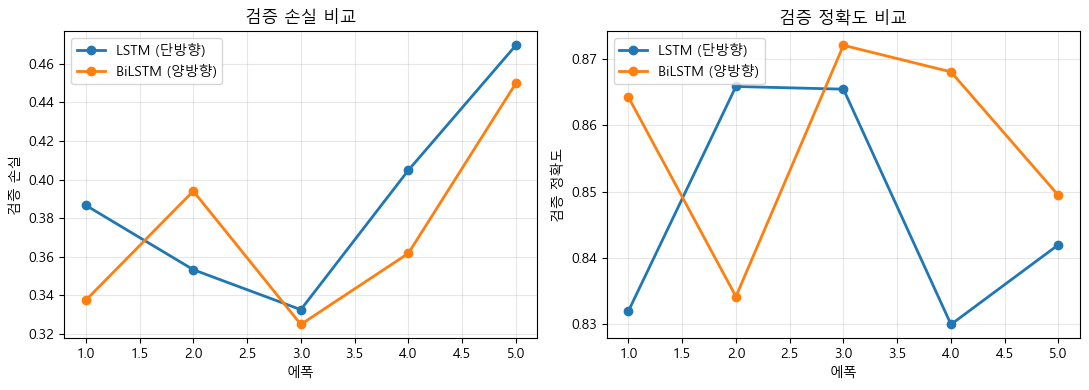

In [25]:
# [과제 1-2] 양방향 LSTM 성능 비교
# 아래에 코드를 작성하세요.
#   순환 층만 Bidirectional(LSTM) 로 바꾸고 나머지 구조는 동일하게 두어
#   검증 정확도 · 파라미터 수 · 학습 시간을 비교한다.

import time


def build_bilstm(units=hidden_dim):
    """build_model('LSTM') 과 구조가 같고 순환 층만 양방향인 모형."""
    model = keras.Sequential([
        keras.layers.Input(shape=(maxlen,)),
        keras.layers.Embedding(vocab_size, embedding_dim, mask_zero=True),
        keras.layers.Bidirectional(keras.layers.LSTM(units)),
        keras.layers.Dense(1, activation='sigmoid'),
    ], name='BiLSTM')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model


EPOCHS_HW12 = 5
BATCH_HW12 = 128

hist_bi, rows_bi = {}, []

for label, builder in [('LSTM (단방향)', lambda: build_model('LSTM')),
                       ('BiLSTM (양방향)', build_bilstm)]:
    tf.random.set_seed(0)              # 초기화 시드를 맞추어 공정하게 비교한다
    m = builder()
    t0 = time.time()
    h = m.fit(x_train_pad, y_train,
              epochs=EPOCHS_HW12, batch_size=BATCH_HW12,
              validation_split=0.2, verbose=0)
    elapsed = time.time() - t0

    hist_bi[label] = h.history
    rows_bi.append((label,
                    m.layers[1].count_params(),     # 순환 층 파라미터 수
                    m.count_params(),               # 전체 파라미터 수
                    max(h.history['val_accuracy']),
                    elapsed))
    print('%-16s 학습 완료 (%.1f 초)' % (label, elapsed))

# ---------------- 비교 표 ----------------
print()
print('%-16s %16s %16s %16s %14s'
      % ('모형', '순환층 파라미터', '전체 파라미터', '최고 검증 정확도', '학습 시간(초)'))
print('-' * 84)
for label, rnn_p, tot_p, acc, sec in rows_bi:
    print('%-16s %16d %16d %16.4f %14.1f' % (label, rnn_p, tot_p, acc, sec))

base = rows_bi[0]
bi = rows_bi[1]
print('\n· 순환 층 파라미터 비율 : %.2f 배' % (bi[1] / base[1]))
print('· 학습 시간 비율       : %.2f 배' % (bi[4] / base[4]))
print('· 검증 정확도 차이     : %+.4f (%+.2f%%p)'
      % (bi[3] - base[3], 100 * (bi[3] - base[3])))

# ---------------- 학습 곡선 ----------------
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
for label, h in hist_bi.items():
    ep = np.arange(1, len(h['loss']) + 1)
    plt.plot(ep, h['val_loss'], '-o', lw=2, label=label)
plt.xlabel('에폭'); plt.ylabel('검증 손실'); plt.title('검증 손실 비교')
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
for label, h in hist_bi.items():
    ep = np.arange(1, len(h['val_accuracy']) + 1)
    plt.plot(ep, h['val_accuracy'], '-o', lw=2, label=label)
plt.xlabel('에폭'); plt.ylabel('검증 정확도'); plt.title('검증 정확도 비교')
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**과제 1-2 서술형**

**[결과]** 양방향 LSTM은 단방향보다 검증 정확도가 0.8658에서 0.8720으로 0.6%p 정도 올랐다. 그 대신 순환 층 파라미터는 정확히 2배(33,024개 → 66,048개)가 되었고, 학습 시간은 152.8초에서 430.4초로 약 2.8배 늘었다. 비용이 늘어난 만큼 성능이 따라오지는 않았다.

**[해석]** 처음에는 문장을 앞뒤로 모두 읽으면 'not ... good'처럼 뒤에서 뜻이 뒤집히는 표현을 더 잘 잡아 정확도가 크게 오를 것이라고 예상했다. 차이가 작았던 이유는 IMDB 감성 분류가 문장 구조보다 'brilliant', 'terrible' 같은 감정어가 나오는지에 크게 기대는 과제이기 때문이라고 생각한다. 단방향 LSTM도 문장 끝까지 읽은 은닉 상태로 판단하므로 이미 리뷰 전체를 한 번 훑은 셈이고, 역방향 층이 더해 주는 것은 리뷰 앞부분을 더 선명하게 기억하는 정도에 그친다. 또 200단어 뒤를 잘라 냈기 때문에, 역방향 층이 먼저 읽어야 할 리뷰의 결말 부분이 빠진 경우도 많았을 것이다.

학습 시간이 파라미터 비율(2배)보다 더 늘어난 것은 역방향 층도 시점 순서대로 따로 계산해야 하고, GPU 없이 CPU로 학습해 두 방향을 병렬로 처리하는 이점이 적었기 때문으로 보인다.

**[결론]** 양방향 구조는 문장 전체를 미리 볼 수 있을 때만 쓸 수 있어서, 다음 단어 예측이나 실시간 번역처럼 아직 오지 않은 입력을 다루는 과제에는 쓸 수 없다. 이번처럼 정확도 이득이 1%p도 안 된다면 단방향 LSTM이 더 실용적이다. 반대로 개체명 인식처럼 단어 하나하나를 판단할 때 앞뒤 문맥이 모두 중요한 과제에서는 양방향의 장점이 더 클 것이다.


### 과제 1-3. 심층 LSTM 실험 (20점)

LSTM 층을 2 층으로 쌓은 모형을 만들어 1 층 모형과 성능을 비교하라.
(아래 층에는 `return_sequences=True` 를 지정해야 한다.)
층을 깊게 쌓았을 때 성능이 항상 좋아지는지, 그렇지 않다면 이유는 무엇인지 서술하라.


**층 쌓기와 return_sequences**: 순환 층을 여러 개 쌓으려면 아래층이 모든 시점의 출력을 위층에 넘겨야 한다.
- 아래층 `LSTM(64, return_sequences=True)` → `(batch, T, 64)`
- 맨 위층 `LSTM(64)` → `(batch, 64)` (마지막 시점만)
- `dropout=0.3`: 각 시점의 입력 연결을 30%확률로 끊는 규제

Model: "LSTM_2L"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_18 (Embedding)        │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 200, 64)        │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_12 (LSTM)                  │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,113 (2.69 MB)

 Trainable params: 706,113 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

LSTM 1층                  학습 완료


LSTM 2층                  학습 완료


LSTM 2층 + dropout 0.3    학습 완료

모형                              전체 파라미터       학습 정확도       검증 정확도       과적합 간격
--------------------------------------------------------------------------------
LSTM 1층                          673089       0.9178       0.8602       0.0576
LSTM 2층                          706113       0.9260       0.8486       0.0774
LSTM 2층 + dropout 0.3            706113       0.9190       0.8664       0.0526


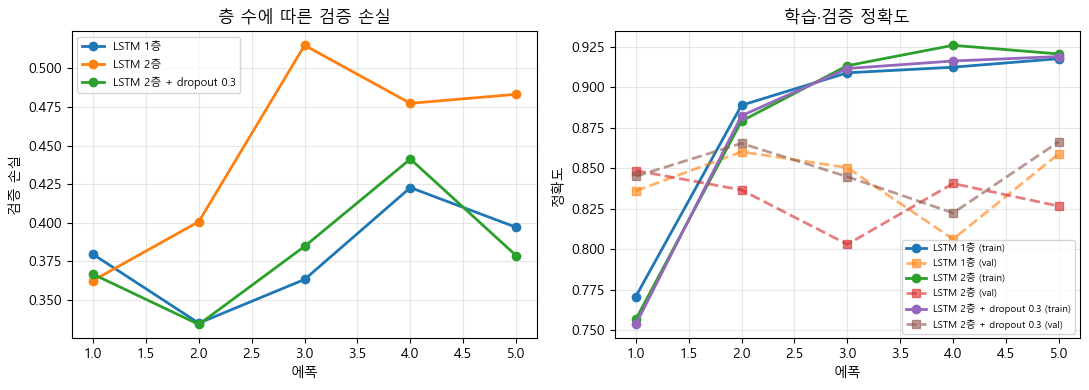

In [26]:
# [과제 1-3] 심층 LSTM 실험
# 아래에 코드를 작성하세요.
#   LSTM 을 2 층으로 쌓아 1 층 모형과 비교한다.
#   아래층은 위층에 '모든 시점의 출력'을 넘겨야 하므로 return_sequences=True 가 필요하다.

def build_stacked_lstm(n_layers=2, units=hidden_dim, dropout=0.0):
    layers = [keras.layers.Input(shape=(maxlen,)),
              keras.layers.Embedding(vocab_size, embedding_dim, mask_zero=True)]
    for i in range(n_layers):
        is_last = (i == n_layers - 1)
        layers.append(keras.layers.LSTM(
            units,
            return_sequences=not is_last,   # 마지막 층만 마지막 은닉 상태 하나를 반환
            dropout=dropout))
    layers.append(keras.layers.Dense(1, activation='sigmoid'))

    model = keras.Sequential(layers, name='LSTM_%dL' % n_layers)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model


# 구조 확인 : 아래층이 (batch, timesteps, units) 를 그대로 넘기는지 본다.
build_stacked_lstm(2).summary()

EPOCHS_HW13 = 5
hist_deep, rows_deep = {}, []

for label, kwargs in [('LSTM 1층', dict(n_layers=1)),
                      ('LSTM 2층', dict(n_layers=2)),
                      ('LSTM 2층 + dropout 0.3', dict(n_layers=2, dropout=0.3))]:
    tf.random.set_seed(0)
    m = build_stacked_lstm(**kwargs)
    h = m.fit(x_train_pad, y_train,
              epochs=EPOCHS_HW13, batch_size=128,
              validation_split=0.2, verbose=0)
    hist_deep[label] = h.history
    tr_acc = max(h.history['accuracy'])
    va_acc = max(h.history['val_accuracy'])
    rows_deep.append((label, m.count_params(), tr_acc, va_acc, tr_acc - va_acc))
    print('%-24s 학습 완료' % label)

print()
print('%-24s %14s %12s %12s %12s'
      % ('모형', '전체 파라미터', '학습 정확도', '검증 정확도', '과적합 간격'))
print('-' * 80)
for label, p, tr, va, gap in rows_deep:
    print('%-24s %14d %12.4f %12.4f %12.4f' % (label, p, tr, va, gap))

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
for label, h in hist_deep.items():
    ep = np.arange(1, len(h['loss']) + 1)
    plt.plot(ep, h['val_loss'], '-o', lw=2, label=label)
plt.xlabel('에폭'); plt.ylabel('검증 손실'); plt.title('층 수에 따른 검증 손실')
plt.legend(fontsize=8); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
for label, h in hist_deep.items():
    ep = np.arange(1, len(h['accuracy']) + 1)
    plt.plot(ep, h['accuracy'], '-o', lw=2, label='%s (train)' % label)
    plt.plot(ep, h['val_accuracy'], '--s', lw=2, alpha=0.6, label='%s (val)' % label)
plt.xlabel('에폭'); plt.ylabel('정확도'); plt.title('학습·검증 정확도')
plt.legend(fontsize=7); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**과제 1-3 서술형**

**[결과]** LSTM을 2층으로 쌓자 학습 정확도는 0.9178에서 0.9260으로 올랐지만, 검증 정확도는 0.8602에서 0.8486으로 오히려 떨어졌다. 같은 2층 구조에 `dropout=0.3`을 더하자 검증 정확도가 0.8664로 세 모형 중 가장 높았다.

**[해석]** 층을 깊게 쌓는다고 성능이 항상 좋아지지는 않았다. 2층 모형은 학습 데이터는 더 잘 맞히면서 검증 성능은 떨어졌으므로, 늘어난 표현력이 일반화가 아니라 학습 데이터 20,000건을 외우는 데 쓰인 것으로 보인다. 검증 손실이 3에폭에 0.51까지 튀고 검증 정확도가 에폭마다 0.80~0.85 사이에서 출렁인 것도, 깊이 방향으로 역전파 경로가 길어지면서 최적화가 불안정해졌다는 신호로 읽었다. 게다가 IMDB 감성 분류는 감정어가 있는지만 봐도 상당 부분 풀리는 비교적 단순한 과제라서, 아래층이 만든 표현을 위층이 한 번 더 추상화할 필요가 크지 않았다고 생각한다.

가장 눈에 띈 것은 dropout을 넣은 2층 모형이 가장 좋았다는 점이다. 깊이 자체가 문제였다기보다, 늘어난 용량을 규제 없이 두었을 때 과적합으로 흘러갔다고 보는 편이 맞다.

**[결론]** 깊이는 데이터 양, 규제, 과제 난도와 함께 맞춰야 효과를 낸다. 기계 번역이나 음성 인식처럼 데이터가 훨씬 많고 구조가 복잡한 과제에서는 깊은 순환망이 이득을 보지만, 이번처럼 작은 데이터에서는 1층 모형이나 규제를 넣은 모형이 더 안전하다. 다만 5에폭, 시드 하나로 비교했고, CPU 학습 특성상 같은 1층 LSTM도 실행마다 검증 정확도가 0.857~0.866 사이로 달라졌다. 그래서 1%p 안팎의 차이는 여러 번 반복해서 확인해야 결론을 낼 수 있다.


### 과제 1-4. 기울기 클리핑 실험 (30점)

`SimpleRNN` 모형을 `maxlen=400` 으로 학습시키면서 옵티마이저에 기울기 클리핑을 적용해 보자.

```python
keras.optimizers.Adam(1e-3, clipnorm=1.0)
```

클리핑을 적용한 경우와 적용하지 않은 경우의 **손실 곡선**을 함께 그리고,
기울기 클리핑이 완화하는 문제가 **소실인지 폭주인지** 근거를 들어 서술하라.


**clipnorm**: Keras 옵티마이저의 인자로, 모든 기울기를 묶은 노름이 기준값을 넘으면 기울기를 그 크기로 줄여서(방향은 유지) 갱신한다.
- `Adam(1e-3, clipnorm=1.0)`: $\|g\|>1$이면 $g \leftarrow g/\|g\|$, 아니면 그대로
- `clipvalue`: 원소별로 자르는 방식 (방향이 바뀔 수 있음)

**tf.GradientTape**: TensorFlow의 자동 미분 도구로, `with` 블록 안의 연산을 기록했다가 `tape.gradient(loss, vars)`로 기울기를 구한다.
- `tf.linalg.global_norm(grads)`: 기울기 리스트 전체의 L2노름 (clipnorm이 비교하는 값)

실험용 학습 데이터 shape : (25000, 400)


클리핑 없음          최종 학습 손실 0.0479 / 최고 검증 정확도 0.7964


clipnorm = 1.0  최종 학습 손실 0.1569 / 최고 검증 정확도 0.8562


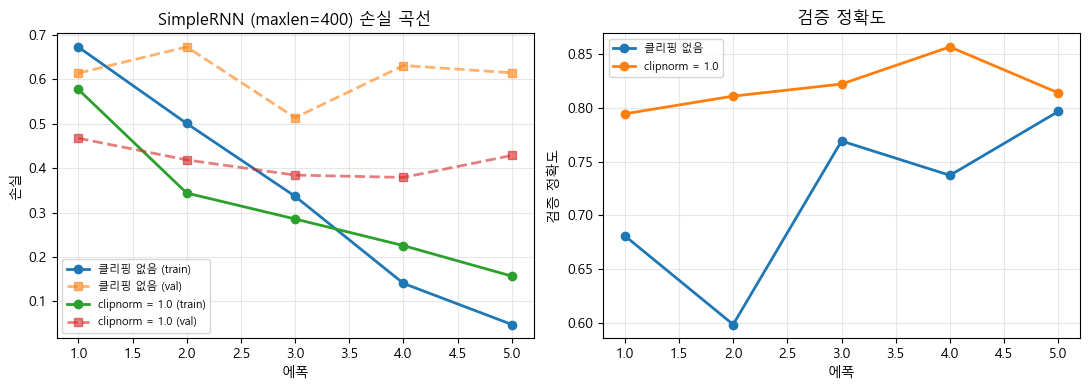


[기울기 전역 노름 측정 : 클리핑 전, 60 배치]
  중앙값 0.767 | 평균 1.556 | 최댓값 25.776 | 1.0 초과 비율 30.0%


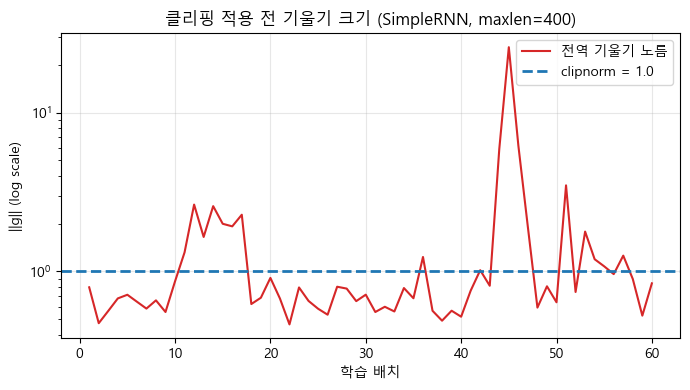

In [27]:
# [과제 1-4] 기울기 클리핑 실험
# 아래에 코드를 작성하세요.
#   maxlen=400 (펼치는 시점 400) 에서 SimpleRNN 을 학습하며
#   클리핑 유무에 따른 손실 곡선을 비교한다.

MAXLEN_HW14 = 400

x_train_400 = pad_sequences(x_train, maxlen=MAXLEN_HW14,
                            padding='post', truncating='post')
print('실험용 학습 데이터 shape :', x_train_400.shape)


def build_simplernn_400(clipnorm=None, units=hidden_dim):
    """clipnorm=None 이면 클리핑 없음, 실수를 주면 전역 노름 클리핑을 적용."""
    model = keras.Sequential([
        keras.layers.Input(shape=(MAXLEN_HW14,)),
        keras.layers.Embedding(vocab_size, embedding_dim, mask_zero=True),
        keras.layers.SimpleRNN(units),
        keras.layers.Dense(1, activation='sigmoid'),
    ], name='SimpleRNN_%s' % ('clip' if clipnorm else 'noclip'))
    model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=clipnorm),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model


EPOCHS_HW14 = 5
hist_clip = {}

for label, cn in [('클리핑 없음', None), ('clipnorm = 1.0', 1.0)]:
    tf.random.set_seed(0)
    m = build_simplernn_400(clipnorm=cn)
    h = m.fit(x_train_400, y_train,
              epochs=EPOCHS_HW14, batch_size=128,
              validation_split=0.2, verbose=0)
    hist_clip[label] = h.history
    print('%-14s  최종 학습 손실 %.4f / 최고 검증 정확도 %.4f'
          % (label, h.history['loss'][-1], max(h.history['val_accuracy'])))

# ---------------- 손실 곡선 ----------------
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
for label, h in hist_clip.items():
    ep = np.arange(1, len(h['loss']) + 1)
    plt.plot(ep, h['loss'], '-o', lw=2, label='%s (train)' % label)
    plt.plot(ep, h['val_loss'], '--s', lw=2, alpha=0.6, label='%s (val)' % label)
plt.xlabel('에폭'); plt.ylabel('손실'); plt.title('SimpleRNN (maxlen=400) 손실 곡선')
plt.legend(fontsize=8); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
for label, h in hist_clip.items():
    ep = np.arange(1, len(h['val_accuracy']) + 1)
    plt.plot(ep, h['val_accuracy'], '-o', lw=2, label=label)
plt.xlabel('에폭'); plt.ylabel('검증 정확도'); plt.title('검증 정확도')
plt.legend(fontsize=8); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ---------------- 근거 : 클리핑 전 기울기의 전역 노름을 직접 측정 ----------------
#   클리핑이 '무엇을' 막고 있는지 확인하려면 잘리기 전 기울기 크기를 보아야 한다.
tf.random.set_seed(0)
probe = build_simplernn_400(clipnorm=None)
probe_opt = keras.optimizers.Adam(1e-3)
bce = keras.losses.BinaryCrossentropy()
y_float = np.asarray(y_train).astype('float32')

grad_norms = []
for i in range(60):
    xb = x_train_400[i * 128:(i + 1) * 128]
    yb = y_float[i * 128:(i + 1) * 128]
    with tf.GradientTape() as tape:
        loss = bce(yb, tf.reshape(probe(xb, training=True), [-1]))
    grads = tape.gradient(loss, probe.trainable_variables)
    grad_norms.append(float(tf.linalg.global_norm(grads)))
    probe_opt.apply_gradients(zip(grads, probe.trainable_variables))

grad_norms = np.array(grad_norms)
print('\n[기울기 전역 노름 측정 : 클리핑 전, 60 배치]')
print('  중앙값 %.3f | 평균 %.3f | 최댓값 %.3f | 1.0 초과 비율 %.1f%%'
      % (np.median(grad_norms), grad_norms.mean(), grad_norms.max(),
         100 * np.mean(grad_norms > 1.0)))

plt.figure(figsize=(7, 4))
plt.semilogy(np.arange(1, len(grad_norms) + 1), grad_norms, lw=1.5,
             color='tab:red', label='전역 기울기 노름')
plt.axhline(1.0, ls='--', color='tab:blue', lw=2, label='clipnorm = 1.0')
plt.xlabel('학습 배치'); plt.ylabel('||g|| (log scale)')
plt.title('클리핑 적용 전 기울기 크기 (SimpleRNN, maxlen=400)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**과제 1-4 서술형**

**[결과]** maxlen=400에서 SimpleRNN을 학습할 때 `clipnorm=1.0`을 적용하자 최고 검증 정확도가 0.7964에서 0.8562로 약 6%p 올랐고, 검증 손실도 0.4 안팎에서 안정적으로 움직였다. 클리핑이 없을 때는 학습 손실이 0.05까지 빠르게 떨어진 반면, 검증 손실은 0.5~0.67 사이에서 위아래로 튀었다.

**[해석]** 기울기 클리핑이 완화하는 것은 폭주다. 클리핑은 기울기 노름이 기준값 1.0을 넘을 때만 크기를 줄이고, 그보다 작은 기울기는 건드리지 않는다. 그러니 기울기가 0으로 사라지는 소실에는 원리상 도움을 줄 수 없고, 다룰 수 있는 것은 너무 커진 기울기, 즉 폭주뿐이다. 실제로 클리핑 없이 60배치 동안 기울기 노름을 재 보니 평소에는 중앙값 0.77 정도로 얌전하다가, 45번째 배치 부근에서 25.8까지 갑자기 치솟았다. 이런 순간에 가중치가 한꺼번에 크게 움직이면 그동안 배운 것이 흐트러진다. 클리핑 없는 모형의 검증 정확도가 0.68에서 0.60으로 떨어졌다가 다시 오르는 식으로 출렁인 것도 이 때문이라고 해석했다.

흥미로운 점은 클리핑을 쓴 쪽의 학습 손실이 오히려 더 높게 끝났다는 것이다(0.157 대 0.048). 클리핑이 학습을 빠르게 만든 것이 아니라, 갑작스러운 큰 갱신을 막아 학습 데이터를 덜 외우고 더 고르게 배우도록 만든 셈이다.

**[결론]** 기울기 클리핑은 폭주를 막는 안전장치이지 소실의 해결책은 아니다. 클리핑을 적용한 SimpleRNN도 같은 길이에서 LSTM이 기록한 0.8788에는 미치지 못했는데, 먼 과거의 신호가 사라지는 소실 문제는 여전히 남아 있기 때문이다. 소실은 LSTM·GRU의 게이트처럼 기울기가 흐르는 경로 자체를 바꾸어야 해결된다.


### 마치며

이번 실습에서는 RNN 과 LSTM 의 순전파를 직접 구현하여 내부 연산을 확인하고,
기울기 소실 현상을 수치적으로 관찰한 뒤, 실제 데이터에서 순환 층의 종류에 따른 성능 차이를 비교하였다.

지금까지 다룬 구조는 모두 **입력 시점과 출력 시점이 대응되는** 문제였다.
다음 실습(실습 2)에서는 입력과 출력의 길이가 서로 다른 문제, 즉
**순차열 대 순차열(Seq2Seq)** 구조를 이용한 기계 번역을 구현한다.